In [10]:
import requests

headers = {
    'sec-ch-ua-platform': '"Windows"',
    'Referer': 'https://www.fotmob.com/en-GB/players/1225025/jonny-yull',
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/150.0.0.0 Safari/537.36',
    'x-mas': 'eyJib2R5Ijp7InVybCI6Ii9hcGkvZGF0YS9wbGF5ZXJEYXRhP2lkPTEyMjUwMjUiLCJjb2RlIjoxNzg0NjI3MTUzNDUxLCJmb28iOiJwcm9kdWN0aW9uOmM5NDE1YjM0NzI4NmI4N2ZmMzYzYWRkNTJiYjNlNDA3NzFmMDU0MmYifSwic2lnbmF0dXJlIjoiQzE5NkI5MjQ3Q0JDNzNGOUMxRUM3NTIxRjgyOEIwRTUifQ==',
    'sec-ch-ua': '"Not;A=Brand";v="8", "Chromium";v="150", "Google Chrome";v="150"',
    'sec-ch-ua-mobile': '?0',
}

params = {
    'id': '1225025',
}

response = requests.get('https://www.fotmob.com/api/data/playerData', params=params, headers=headers)

In [11]:
import os

# os.chdir('/content/drive/MyDrive/Football Data Analysis/Jonny Yull')

In [12]:
import pandas as pd

data = response.json()

In [13]:
name = data['name']

birth_date = data['birthDate']['utcTime'][:10]

team = data['primaryTeam']['teamName']

detail_rows = pd.DataFrame({'title': ['Name', 'Birth Date', 'Team'],
               'value.fallback': [name, birth_date, team]})

details_data = data['playerInformation']
details_norm_df = pd.json_normalize(details_data)
details_df = pd.DataFrame(details_norm_df)
details_df = details_df.loc[:, ['title', 'value.fallback']]
details_df = pd.concat([detail_rows, details_df])
details_df

,title,value.fallback
0,Name,Jonny Yull
1,Birth Date,2005-03-05
2,Team,Adelaide United
0,Height,174 cm
1,Shirt,12
2,Age,21
3,Preferred foot,Right
4,Country,Australia
5,Market value,€530.8k


In [14]:
# details_df.to_excel('jy_details_df.xlsx', index=False)

In [15]:
pos_data = data['positionDescription']['positions']

pos_norm_df = pd.json_normalize(pos_data)

pos_df = pd.DataFrame(pos_norm_df)

pos_df = pos_df.iloc[:, :4]

pos_df

,occurences,position,isMainPosition,strPos.label
0,5,72,False,Right Midfielder
1,2,74,False,Central Midfielder
2,2,78,False,Left Midfielder
3,4,82,False,Right Winger
4,10,88,True,Left Winger
5,1,106,False,Striker


In [16]:
# pos_df.to_excel('jy_pos_df.xlsx', index=False)

In [17]:
heatmap_data = data['firstSeasonStats']['heatmap']['coordinates']

heatmap_df = pd.DataFrame(heatmap_data)

heatmap_df

,x,y
0,78.99,51.50
1,43.55,45.40
2,91.10,56.06
3,62.21,43.10
4,62.66,42.99
5,74.94,46.24
6,58.19,52.06
7,43.66,49.05
8,39.63,53.67
9,61.24,61.57


In [18]:
# heatmap_df.to_excel('jy_heatmap.xlsx', index=False)

In [19]:
value_data = data['marketValues']['values']

In [20]:
value_df = pd.DataFrame(value_data)

In [21]:
value_df['date'] = value_df['date'].str[:10]

In [22]:
# value_df.to_excel('jy_mv_df.xlsx', index=False)

In [23]:
season_basic_data = data['mainLeague']['stats']

In [24]:
season_basic_df = pd.DataFrame(season_basic_data)

In [25]:
# season_basic_df.to_excel('jy_basic_stats.xlsx', index=False)

In [26]:
stats_data = data['firstSeasonStats']['statsSection']['items']
stats_df = pd.DataFrame()

for i in range(len(stats_data)):

    stats_df = pd.concat([stats_df, pd.DataFrame(stats_data[i]['items'])])

In [27]:
stats_df = stats_df.sort_values('percentileRankPer90', ascending=False)

In [28]:
stats_df

,localizedTitleId,per90,percentileRank,percentileRankPer90,statFormat,statValue,title
3,aerials_won_percent,100.000000,100.000000,100.000000,percent,100.0,Aerials won %
0,yellow_cards,0.000000,100.000000,100.000000,number,0,Yellow cards
6,dispossessed,1.000000,37.209302,62.790698,number,1,Dispossessed
3,successful_passes_accuracy,80.645161,62.790698,62.790698,percent,80.6,Pass accuracy
2,aerials_won,1.000000,58.139535,58.139535,number,1,Aerials won
1,duel_won_percent,50.000000,53.488372,53.488372,percent,50.0,Duels won %
2,successful_passes,25.000000,62.790698,51.162791,number,25,Accurate passes
7,expected_goals_against_while_on_pitch,0.776500,48.837209,51.162791,fraction,0.78,xG against while on pitch
2,fouls,1.000000,25.581395,48.837209,number,1,Fouls committed
5,long_ball_succeeeded_accuracy,50.000000,46.511628,46.511628,percent,50.0,Long ball accuracy


In [29]:
# stats_df.to_excel('jy_stats_df.xlsx', index=False)

In [30]:
shotmap_data = data['firstSeasonStats']['shotmap']
shotmap_df = pd.DataFrame(shotmap_data)

In [31]:
# shotmap_df.to_excel('jy_shotmap.xlsx', index=False)

In [32]:
# SHOTMAP COMPARISON
from mplsoccer import VerticalPitch

pitch = VerticalPitch(
    pitch_type='custom',
    pitch_length=105,
    pitch_width=68,
    half=True,
    pitch_color='#aabb97', 
    line_color='white',
    pad_bottom=0.5           
)

In [44]:
pitch_df = pd.read_excel('jy_shotmap.xlsx')

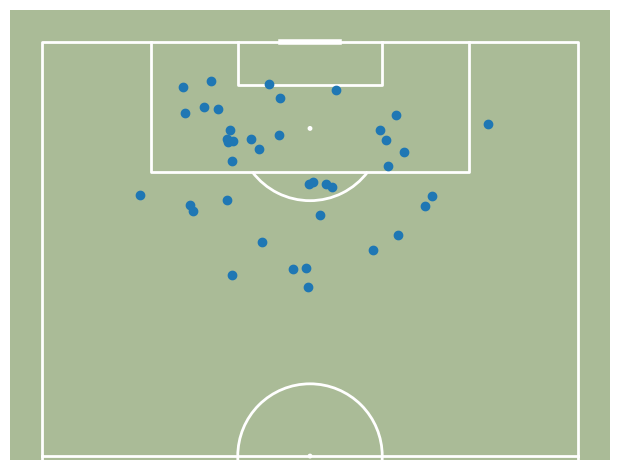

In [45]:
fig, ax = pitch.draw()
pitch.scatter(pitch_df['x'], pitch_df['y'], ax=ax)